# Autonomous Multi-Cloud Resource Orchestration and Self-Healing Infrastructure

## Project implementation notebook

This notebook documents the implemented data pipeline, CPU prediction model, anomaly detection, multi-cloud failure simulation, orchestration policy comparison, and result validation.

**Environment:** Google Colab with Google Drive storage. The code expects the project directory at `/content/drive/MyDrive/Multi_Cloud_Orchestration`.

**Note:** The notebook is organized for review. Some cells are computationally expensive (dataset preprocessing and model training). Existing outputs are retained as recorded evidence; they may not represent a fresh execution in a new runtime.

## 1. Environment and dataset setup

Run the following cells in order when reproducing the pipeline. Kaggle credentials should be provided privately in Colab and must never be committed to GitHub.

In [ ]:

# ============================================================
# MULTI-CLOUD ORCHESTRATION PROJECT
# CELL 1: IMPORTS + DRIVE + KAGGLE + DATASET SETUP
# ============================================================

import os
import sys
import json
import glob
import shutil
import zipfile
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive, files

print("=" * 60)
print("STEP 1: IMPORTING LIBRARIES")
print("=" * 60)

# Install Kaggle CLI only if it is unavailable
if shutil.which("kaggle") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "kaggle"],
        check=True
    )

print("Core libraries ready.")

# ------------------------------------------------------------
# STEP 2: MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

print("\nSTEP 2: CONNECTING GOOGLE DRIVE")

drive.mount("/content/drive")

# Persistent project directory
PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
PROCESSED_DIR = os.path.join(PROJECT_DIR, "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
APP_DIR = os.path.join(PROJECT_DIR, "app")

for folder in [
    DATA_DIR,
    PROCESSED_DIR,
    MODEL_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    CHECKPOINT_DIR,
    APP_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Google Drive connected.")
print("Project folder:", PROJECT_DIR)

# ------------------------------------------------------------
# STEP 3: CONFIGURE KAGGLE API
# ------------------------------------------------------------

print("\nSTEP 3: CONFIGURING KAGGLE API")

KAGGLE_CONFIG_DIR = "/content/.kaggle"
KAGGLE_JSON_PATH = os.path.join(KAGGLE_CONFIG_DIR, "kaggle.json")

os.makedirs(KAGGLE_CONFIG_DIR, exist_ok=True)

# Reuse credentials already configured in this runtime if valid.
# Otherwise ask you to upload your existing kaggle.json.
credentials_ok = False

if os.path.isfile(KAGGLE_JSON_PATH):
    try:
        with open(KAGGLE_JSON_PATH, "r", encoding="utf-8") as f:
            credentials = json.load(f)
        credentials_ok = bool(
            credentials.get("username") and credentials.get("key")
        )
    except (OSError, json.JSONDecodeError):
        credentials_ok = False

if not credentials_ok:
    print("Upload your Kaggle API file when the upload window appears.")
    print("Select your kaggle.json file.")

    uploaded = files.upload()

    if not uploaded:
        raise RuntimeError("No Kaggle API file was uploaded.")

    uploaded_name = next(iter(uploaded))
    with open(uploaded_name, "r", encoding="utf-8") as f:
        credentials = json.load(f)

    if not credentials.get("username") or not credentials.get("key"):
        raise ValueError(
            "Invalid Kaggle JSON. Check that you uploaded kaggle.json."
        )

    shutil.copy2(uploaded_name, KAGGLE_JSON_PATH)

os.chmod(KAGGLE_JSON_PATH, 0o600)
os.environ["KAGGLE_CONFIG_DIR"] = KAGGLE_CONFIG_DIR

print("Kaggle credentials configured.")

# Verify authentication without displaying credentials
auth_test = subprocess.run(
    ["kaggle", "datasets", "list", "-s", "gwa-bitbrains"],
    capture_output=True,
    text=True
)

if auth_test.returncode != 0:
    raise RuntimeError(
        "Kaggle authentication failed. Check your API token and try again.\n"
        + auth_test.stderr[-1500:]
    )

print("Kaggle authentication successful.")

# ------------------------------------------------------------
# STEP 4: DOWNLOAD DATASET ARCHIVE TO GOOGLE DRIVE
# ------------------------------------------------------------

print("\nSTEP 4: CHECKING BITBRAINS DATASET")

DATASET_ID = "gauravdhamane/gwa-bitbrains"

# Download into temporary Colab storage first.
# This avoids writing the entire download directly to Drive.
DOWNLOAD_DIR = "/content/kaggle_download"
os.makedirs(DOWNLOAD_DIR, exist_ok=True)

ZIP_PATH = os.path.join(DATA_DIR, "gwa-bitbrains.zip")

if os.path.isfile(ZIP_PATH) and os.path.getsize(ZIP_PATH) > 0:
    print("Dataset archive already exists in Drive.")
    print("Reusing:", ZIP_PATH)

else:
    print("Downloading Bitbrains dataset from Kaggle...")
    print("This may take some time.")

    download_result = subprocess.run(
        [
            "kaggle", "datasets", "download",
            "-d", DATASET_ID,
            "-p", DOWNLOAD_DIR
        ],
        text=True
    )

    if download_result.returncode != 0:
        raise RuntimeError(
            "Kaggle download failed. Check the error shown above."
        )

    downloaded_zips = glob.glob(
        os.path.join(DOWNLOAD_DIR, "*.zip")
    )

    if not downloaded_zips:
        raise FileNotFoundError(
            "Kaggle finished without producing a ZIP archive."
        )

    downloaded_zip = max(
        downloaded_zips,
        key=os.path.getsize
    )

    # Verify ZIP integrity before copying to Drive
    with zipfile.ZipFile(downloaded_zip, "r") as archive:
        bad_file = archive.testzip()

        if bad_file is not None:
            raise RuntimeError(
                f"Downloaded archive is corrupted: {bad_file}"
            )

        csv_files = [
            name for name in archive.namelist()
            if name.lower().endswith(".csv")
            and not name.endswith("/")
        ]

    shutil.copy2(downloaded_zip, ZIP_PATH)

    print("Archive copied to Google Drive.")

# ------------------------------------------------------------
# STEP 5: VERIFY THE DATASET CONTENTS
# ------------------------------------------------------------

print("\nSTEP 5: VERIFYING DATASET")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    all_names = archive.namelist()

    csv_files = [
        name for name in all_names
        if name.lower().endswith(".csv")
        and not name.endswith("/")
    ]

    faststorage_files = [
        name for name in csv_files
        if name.startswith("fastStorage/2013-8/")
    ]

    bad_file = archive.testzip()

print("Archive size (MB):",
      round(os.path.getsize(ZIP_PATH) / (1024 ** 2), 2))
print("Total CSV files:", len(csv_files))
print("fastStorage/2013-8 CSV files:", len(faststorage_files))
print("ZIP integrity:", "Passed" if bad_file is None else "Failed")

if bad_file is not None:
    raise RuntimeError("The downloaded ZIP archive is corrupted.")

if len(faststorage_files) != 1250:
    raise RuntimeError(
        "Expected 1,250 fastStorage CSV files, but found "
        f"{len(faststorage_files)}. We should inspect the archive "
        "before proceeding."
    )

print("\n" + "=" * 60)
print("SETUP COMPLETE")
print("=" * 60)
print("Dataset saved at:", ZIP_PATH)
print("Project files will be stored in Google Drive.")
print("Next: resumable CSV preprocessing and checkpoints.")


STEP 1: IMPORTING LIBRARIES
Core libraries ready.

STEP 2: CONNECTING GOOGLE DRIVE
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected.
Project folder: /content/drive/MyDrive/Multi_Cloud_Orchestration

STEP 3: CONFIGURING KAGGLE API
Upload your Kaggle API file when the upload window appears.
Select your kaggle.json file.


Saving kaggle.json to kaggle (1).json
Kaggle credentials configured.
Kaggle authentication successful.

STEP 4: CHECKING BITBRAINS DATASET
This may take some time.
Archive copied to Google Drive.

STEP 5: VERIFYING DATASET
Archive size (MB): 129.23
Total CSV files: 1250
fastStorage/2013-8 CSV files: 1250
ZIP integrity: Passed

SETUP COMPLETE
Dataset saved at: /content/drive/MyDrive/Multi_Cloud_Orchestration/data/gwa-bitbrains.zip
Project files will be stored in Google Drive.
Next: resumable CSV preprocessing and checkpoints.


## 2. Bitbrains data preprocessing

Resumable preprocessing of the VM traces and checkpoint/manifest creation.

In [ ]:

# ============================================================
# CELL 2: RESUMABLE BITBRAINS DATA PREPROCESSING
# ============================================================

import os
import json
import zipfile
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
PROCESSED_DIR = os.path.join(PROJECT_DIR, "processed")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

ZIP_PATH = os.path.join(DATA_DIR, "gwa-bitbrains.zip")
MANIFEST_PATH = os.path.join(
    CHECKPOINT_DIR, "preprocessing_manifest.csv"
)

if not os.path.isfile(ZIP_PATH):
    raise FileNotFoundError(
        "Dataset ZIP not found. Run Cell 1 first."
    )

# Required source columns
REQUIRED_COLUMNS = [
    "Timestamp [ms]",
    "CPU usage [%]",
    "Memory usage [KB]",
    "Disk read throughput [KB/s]",
    "Disk write throughput [KB/s]",
    "Network received throughput [KB/s]",
    "Network transmitted throughput [KB/s]",
]

FEATURE_COLUMNS = [
    "cpu_percent",
    "cpu_lag_1",
    "cpu_lag_2",
    "cpu_lag_3",
    "memory_usage_kb",
    "disk_read_kbps",
    "disk_write_kbps",
    "network_received_kbps",
    "network_transmitted_kbps",
    "hour_utc",
    "minute_utc",
]

TARGET_COLUMN = "target_cpu_next"

# Load previous progress so completed files can be skipped
if os.path.isfile(MANIFEST_PATH):
    previous = pd.read_csv(MANIFEST_PATH)
    completed = set(
        previous.loc[
            (previous["status"] == "success")
            & (previous["valid_rows"] > 0),
            "source_file"
        ].astype(str)
    )
    manifest_rows = previous.to_dict("records")
else:
    completed = set()
    manifest_rows = []

# Keep only the latest manifest record for each source file
manifest_by_file = {
    str(row["source_file"]): row
    for row in manifest_rows
}

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    source_files = sorted([
        name for name in archive.namelist()
        if name.startswith("fastStorage/2013-8/")
        and name.lower().endswith(".csv")
    ])

    print("Source VM files:", len(source_files))
    print("Previously completed:", len(completed))

    for source_file in tqdm(source_files, desc="Processing VMs"):
        output_name = source_file.replace("/", "__") + ".gz"
        output_path = os.path.join(PROCESSED_DIR, output_name)

        # Skip a previously completed file only if output exists
        if source_file in completed and os.path.isfile(output_path):
            continue

        try:
            with archive.open(source_file) as file_obj:
                df = pd.read_csv(file_obj, sep=";")

            df.columns = df.columns.str.strip()

            missing = [
                col for col in REQUIRED_COLUMNS
                if col not in df.columns
            ]

            if missing:
                raise ValueError(f"Missing columns: {missing}")

            # Keep only columns required for this experiment
            df = df[REQUIRED_COLUMNS].copy()

            # Convert values to numeric
            for col in REQUIRED_COLUMNS:
                df[col] = pd.to_numeric(
                    df[col], errors="coerce"
                )

            df = df.dropna(subset=REQUIRED_COLUMNS)
            df = df.sort_values("Timestamp [ms]")
            df = df.drop_duplicates(
                subset=["Timestamp [ms]"], keep="last"
            ).reset_index(drop=True)

            if len(df) < 5:
                raise ValueError("Not enough valid observations.")

            # Timestamp values in this trace behave like Unix seconds,
            # despite the source header saying milliseconds.
            timestamps = df["Timestamp [ms]"]
            datetime_utc = pd.to_datetime(
                timestamps, unit="s", utc=True, errors="coerce"
            )

            df["datetime"] = datetime_utc
            df = df.dropna(subset=["datetime"]).reset_index(drop=True)

            df["cpu_percent"] = df["CPU usage [%]"]
            df["memory_usage_kb"] = df["Memory usage [KB]"]
            df["disk_read_kbps"] = df["Disk read throughput [KB/s]"]
            df["disk_write_kbps"] = df["Disk write throughput [KB/s]"]
            df["network_received_kbps"] = (
                df["Network received throughput [KB/s]"]
            )
            df["network_transmitted_kbps"] = (
                df["Network transmitted throughput [KB/s]"]
            )

            df["cpu_lag_1"] = df["cpu_percent"].shift(1)
            df["cpu_lag_2"] = df["cpu_percent"].shift(2)
            df["cpu_lag_3"] = df["cpu_percent"].shift(3)

            # Predict the next observation's CPU usage
            df[TARGET_COLUMN] = df["cpu_percent"].shift(-1)

            # Use only consecutive observations approximately 5 minutes apart.
            # This prevents lag/target examples from crossing long gaps.
            interval = timestamps.diff()
            previous_gap_1 = interval
            previous_gap_2 = interval.shift(1)
            previous_gap_3 = interval.shift(2)
            next_gap = interval.shift(-1)

            regular = (
                previous_gap_1.le(301)
                & previous_gap_2.le(301)
                & previous_gap_3.le(301)
                & next_gap.le(301)
            )

            df["hour_utc"] = df["datetime"].dt.hour
            df["minute_utc"] = df["datetime"].dt.minute

            df["vm_id"] = source_file

            # Keep timestamp and VM identity for later simulation
            keep_columns = [
                "vm_id",
                "datetime",
                "cpu_percent",
            ] + FEATURE_COLUMNS[1:] + [TARGET_COLUMN]

            output_df = df.loc[
                regular,
                keep_columns
            ].replace([np.inf, -np.inf], np.nan).dropna()

            output_df.to_csv(
                output_path,
                index=False,
                compression="gzip"
            )

            manifest_by_file[source_file] = {
                "source_file": source_file,
                "output_file": output_name,
                "raw_rows": len(df),
                "valid_rows": len(output_df),
                "status": "success",
                "error": ""
            }

        except Exception as exc:
            manifest_by_file[source_file] = {
                "source_file": source_file,
                "output_file": output_name,
                "raw_rows": 0,
                "valid_rows": 0,
                "status": "failed",
                "error": str(exc)[:500]
            }

        # Save progress after every VM so the run can resume
        pd.DataFrame(
            manifest_by_file.values()
        ).to_csv(MANIFEST_PATH, index=False)

print("\nPREPROCESSING FINISHED")

manifest = pd.read_csv(MANIFEST_PATH)

print("Successful files:",
      int((manifest["status"] == "success").sum()))
print("Failed files:",
      int((manifest["status"] == "failed").sum()))
print("Total valid prediction rows:",
      int(manifest["valid_rows"].sum()))
print("Manifest saved to:", MANIFEST_PATH)

display(manifest["status"].value_counts().to_frame("file_count"))


Source VM files: 1250
Previously completed: 0


Processing VMs:   0%|          | 0/1250 [00:00<?, ?it/s]


PREPROCESSING FINISHED
Successful files: 1250
Failed files: 0
Total valid prediction rows: 10713786
Manifest saved to: /content/drive/MyDrive/Multi_Cloud_Orchestration/checkpoints/preprocessing_manifest.csv


,file_count
status,
success,1250


## 3. VM-level train, validation, and test split

The split is grouped by VM to avoid leakage between partitions.

In [ ]:

# ============================================================
# CELL 3: TRAIN / VALIDATION / TEST SPLIT BY VM
# ============================================================

import os
import json
import pandas as pd
from sklearn.model_selection import train_test_split

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "processed")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

MANIFEST_PATH = os.path.join(
    CHECKPOINT_DIR, "preprocessing_manifest.csv"
)
SPLIT_CSV = os.path.join(
    CHECKPOINT_DIR, "vm_split_manifest.csv"
)
SPLIT_JSON = os.path.join(
    CHECKPOINT_DIR, "vm_split_ids.json"
)

print("Checking preprocessed data...")

manifest = pd.read_csv(MANIFEST_PATH)

successful = manifest[
    (manifest["status"] == "success")
    & (manifest["valid_rows"] > 0)
].copy()

# Use only files whose processed output actually exists
successful["processed_path"] = successful["output_file"].apply(
    lambda name: os.path.join(PROCESSED_DIR, name)
)
successful = successful[
    successful["processed_path"].apply(os.path.isfile)
].copy()

vm_ids = sorted(successful["output_file"].tolist())

print("Usable processed VM files:", len(vm_ids))

if len(vm_ids) != 1250:
    raise RuntimeError(
        f"Expected 1250 usable VM files, found {len(vm_ids)}."
    )

# First reserve 20% of VMs for the final test set
train_val_ids, test_ids = train_test_split(
    vm_ids,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

# Split the remaining 80% into 65% training and 15% validation
train_ids, val_ids = train_test_split(
    train_val_ids,
    test_size=0.1875,
    random_state=42,
    shuffle=True
)

# Verify no VM appears in multiple splits
assert set(train_ids).isdisjoint(val_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(val_ids).isdisjoint(test_ids)

assert len(train_ids) + len(val_ids) + len(test_ids) == 1250

split_map = {}

for vm_id in train_ids:
    split_map[vm_id] = "train"

for vm_id in val_ids:
    split_map[vm_id] = "validation"

for vm_id in test_ids:
    split_map[vm_id] = "test"

split_df = successful[
    ["source_file", "output_file", "valid_rows"]
].copy()

split_df["split"] = split_df["output_file"].map(split_map)

# Save the split manifest to persistent Drive storage
split_df.to_csv(SPLIT_CSV, index=False)

with open(SPLIT_JSON, "w", encoding="utf-8") as f:
    json.dump(
        {
            "random_state": 42,
            "method": "VM-level train/validation/test split",
            "train": sorted(train_ids),
            "validation": sorted(val_ids),
            "test": sorted(test_ids)
        },
        f,
        indent=2
    )

# Count rows assigned to each split (not loading all data into RAM)
row_counts = (
    split_df.groupby("split")["valid_rows"]
    .agg(["count", "sum"])
    .reindex(["train", "validation", "test"])
)

print("\nSPLIT COMPLETED")
print("Training VMs:", len(train_ids))
print("Validation VMs:", len(val_ids))
print("Testing VMs:", len(test_ids))

print("\nVM and prediction-row counts:")
display(row_counts)

print("\nVM split manifest:", SPLIT_CSV)
print("Reusable split IDs:", SPLIT_JSON)

print("\nAll checks passed: no VM leakage between splits.")


Checking preprocessed data...
Usable processed VM files: 1250

SPLIT COMPLETED
Training VMs: 812
Validation VMs: 188
Testing VMs: 250

VM and prediction-row counts:


,count,sum
split,,
train,812,6944346
validation,188,1609678
test,250,2159762



VM split manifest: /content/drive/MyDrive/Multi_Cloud_Orchestration/checkpoints/vm_split_manifest.csv
Reusable split IDs: /content/drive/MyDrive/Multi_Cloud_Orchestration/checkpoints/vm_split_ids.json

All checks passed: no VM leakage between splits.


## 4. Train the CPU prediction model

Train the Random Forest model and compare it with the persistence baseline.

In [ ]:

# ============================================================
# CELL 4: PREPARE TRAINING DATA AND TRAIN RANDOM FOREST
# ============================================================

import os
import time
import json
import joblib
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "processed")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

SPLIT_CSV = os.path.join(CHECKPOINT_DIR, "vm_split_manifest.csv")
MODEL_PATH = os.path.join(MODEL_DIR, "random_forest_cpu.joblib")
METRICS_PATH = os.path.join(RESULTS_DIR, "validation_metrics.csv")

FEATURE_COLUMNS = [
    "cpu_percent",
    "cpu_lag_1",
    "cpu_lag_2",
    "cpu_lag_3",
    "memory_usage_kb",
    "disk_read_kbps",
    "disk_write_kbps",
    "network_received_kbps",
    "network_transmitted_kbps",
    "hour_utc",
    "minute_utc",
]
TARGET_COLUMN = "target_cpu_next"

MAX_ROWS_PER_VM = 2000
SEED = 42

split_df = pd.read_csv(SPLIT_CSV)

def load_sample(split_name, max_rows_per_vm=2000):
    """Load a deterministic sample from each VM in one split."""
    selected = split_df[split_df["split"] == split_name]
    frames = []

    for row in tqdm(
        selected.itertuples(index=False),
        total=len(selected),
        desc=f"Loading {split_name}"
    ):
        path = os.path.join(PROCESSED_DIR, row.output_file)
        df = pd.read_csv(path)

        df = df.replace([np.inf, -np.inf], np.nan)
        df = df.dropna(
            subset=FEATURE_COLUMNS + [TARGET_COLUMN]
        )

        if len(df) > max_rows_per_vm:
            df = df.sample(
                n=max_rows_per_vm,
                random_state=SEED
            )

        frames.append(df[FEATURE_COLUMNS + [TARGET_COLUMN]])

    if not frames:
        raise RuntimeError(f"No data found for {split_name}.")

    result = pd.concat(frames, ignore_index=True)

    X = result[FEATURE_COLUMNS].astype(np.float32)
    y = result[TARGET_COLUMN].astype(np.float32)

    return X, y

# Sample only training and validation VMs.
# Test VMs are deliberately not loaded in this cell.
X_train, y_train = load_sample("train", MAX_ROWS_PER_VM)
X_val, y_val = load_sample("validation", MAX_ROWS_PER_VM)

print("\nTraining examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Feature count:", len(FEATURE_COLUMNS))

# Train Random Forest
print("\nTraining Random Forest...")
start_time = time.time()

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    random_state=SEED,
    n_jobs=-1
)

model.fit(X_train, y_train)
training_seconds = time.time() - start_time

# Validation predictions
print("Evaluating on validation data...")
predictions = model.predict(X_val)

rf_mae = mean_absolute_error(y_val, predictions)
rf_rmse = np.sqrt(mean_squared_error(y_val, predictions))

# Persistence baseline: predict next CPU usage equals current CPU usage
baseline_predictions = X_val["cpu_percent"].to_numpy()

baseline_mae = mean_absolute_error(y_val, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_predictions)
)

metrics = pd.DataFrame([
    {
        "model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "training_seconds": training_seconds,
        "validation_examples": len(y_val)
    },
    {
        "model": "Persistence Baseline",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "training_seconds": 0.0,
        "validation_examples": len(y_val)
    }
])

# Persist the model and validation metrics
joblib.dump(model, MODEL_PATH)
metrics.to_csv(METRICS_PATH, index=False)

print("\nVALIDATION RESULTS")
display(metrics)

print("\nRandom Forest saved:", MODEL_PATH)
print("Metrics saved:", METRICS_PATH)
print("Training time (minutes):", round(training_seconds / 60, 2))

if rf_mae < baseline_mae:
    print("Validation finding: Random Forest has lower MAE than baseline.")
else:
    print("Validation finding: baseline has lower or equal MAE.")


Loading train:   0%|          | 0/812 [00:00<?, ?it/s]

Loading validation:   0%|          | 0/188 [00:00<?, ?it/s]


Training examples: 1600277
Validation examples: 372190
Feature count: 11

Training Random Forest...
Evaluating on validation data...

VALIDATION RESULTS


,model,MAE,RMSE,training_seconds,validation_examples
0,Random Forest,0.668734,3.283273,448.232243,372190
1,Persistence Baseline,0.717759,4.563691,0.000000,372190



Random Forest saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/models/random_forest_cpu.joblib
Metrics saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/results/validation_metrics.csv
Training time (minutes): 7.47
Validation finding: Random Forest has lower MAE than baseline.


## 5. Evaluate on held-out VMs

Report final test-set metrics on unseen VMs.

In [ ]:

# ============================================================
# CELL 5: FINAL TEST EVALUATION ON UNSEEN VMs
# ============================================================

import os
import time
import joblib
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "processed")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

MODEL_PATH = os.path.join(MODEL_DIR, "random_forest_cpu.joblib")
SPLIT_CSV = os.path.join(CHECKPOINT_DIR, "vm_split_manifest.csv")
TEST_METRICS_PATH = os.path.join(RESULTS_DIR, "test_metrics.csv")

FEATURE_COLUMNS = [
    "cpu_percent", "cpu_lag_1", "cpu_lag_2", "cpu_lag_3",
    "memory_usage_kb", "disk_read_kbps", "disk_write_kbps",
    "network_received_kbps", "network_transmitted_kbps",
    "hour_utc", "minute_utc"
]
TARGET_COLUMN = "target_cpu_next"

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError("Trained model not found. Run Cell 4 first.")

model = joblib.load(MODEL_PATH)
split_df = pd.read_csv(SPLIT_CSV)
test_files = split_df[split_df["split"] == "test"]

# Accumulate error sums instead of storing all test predictions
total_rows = 0
sum_abs_rf = 0.0
sum_sq_rf = 0.0
sum_abs_baseline = 0.0
sum_sq_baseline = 0.0

start_time = time.time()

for row in tqdm(test_files.itertuples(index=False),
                total=len(test_files), desc="Testing unseen VMs"):

    path = os.path.join(PROCESSED_DIR, row.output_file)
    df = pd.read_csv(path)

    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=FEATURE_COLUMNS + [TARGET_COLUMN])

    if df.empty:
        continue

    X = df[FEATURE_COLUMNS].astype(np.float32)
    y = df[TARGET_COLUMN].to_numpy(dtype=np.float64)

    predictions = model.predict(X).astype(np.float64)
    baseline = X["cpu_percent"].to_numpy(dtype=np.float64)

    rf_errors = predictions - y
    baseline_errors = baseline - y

    sum_abs_rf += np.abs(rf_errors).sum()
    sum_sq_rf += np.square(rf_errors).sum()

    sum_abs_baseline += np.abs(baseline_errors).sum()
    sum_sq_baseline += np.square(baseline_errors).sum()

    total_rows += len(y)

if total_rows == 0:
    raise RuntimeError("No valid test examples were evaluated.")

rf_mae = sum_abs_rf / total_rows
rf_rmse = np.sqrt(sum_sq_rf / total_rows)

baseline_mae = sum_abs_baseline / total_rows
baseline_rmse = np.sqrt(sum_sq_baseline / total_rows)

test_metrics = pd.DataFrame([
    {
        "model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "test_examples": total_rows
    },
    {
        "model": "Persistence Baseline",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "test_examples": total_rows
    }
])

test_metrics.to_csv(TEST_METRICS_PATH, index=False)

print("\nFINAL TEST RESULTS")
display(test_metrics)

print("Test VMs:", len(test_files))
print("Test examples evaluated:", total_rows)
print("Evaluation time (minutes):",
      round((time.time() - start_time) / 60, 2))
print("Saved:", TEST_METRICS_PATH)

if rf_mae < baseline_mae:
    print("Test finding: Random Forest has lower MAE than baseline.")
else:
    print("Test finding: baseline has lower or equal MAE.")

if rf_rmse < baseline_rmse:
    print("Test finding: Random Forest has lower RMSE than baseline.")
else:
    print("Test finding: baseline has lower or equal RMSE.")


Testing unseen VMs:   0%|          | 0/250 [00:00<?, ?it/s]


FINAL TEST RESULTS


,model,MAE,RMSE,test_examples
0,Random Forest,0.697132,3.620143,2159762
1,Persistence Baseline,0.750802,4.812114,2159762


Test VMs: 250
Test examples evaluated: 2159762
Evaluation time (minutes): 0.41
Saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/results/test_metrics.csv
Test finding: Random Forest has lower MAE than baseline.
Test finding: Random Forest has lower RMSE than baseline.


## 6. Train the anomaly detector

Train and save the Isolation Forest model.

In [ ]:

# ============================================================
# CELL 6: TRAIN ANOMALY DETECTOR (ISOLATION FOREST)
# ============================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from sklearn.ensemble import IsolationForest

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "processed")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

SPLIT_CSV = os.path.join(CHECKPOINT_DIR, "vm_split_manifest.csv")
ANOMALY_MODEL_PATH = os.path.join(
    MODEL_DIR, "isolation_forest.joblib"
)
ANOMALY_METRICS_PATH = os.path.join(
    RESULTS_DIR, "anomaly_detector_info.csv"
)

FEATURE_COLUMNS = [
    "cpu_percent", "cpu_lag_1", "cpu_lag_2", "cpu_lag_3",
    "memory_usage_kb", "disk_read_kbps", "disk_write_kbps",
    "network_received_kbps", "network_transmitted_kbps",
    "hour_utc", "minute_utc"
]

MAX_ROWS_PER_VM = 1000
SEED = 42

split_df = pd.read_csv(SPLIT_CSV)
train_files = split_df[split_df["split"] == "train"]

frames = []

print("Loading a training-only sample for anomaly detection...")

for row in tqdm(
    train_files.itertuples(index=False),
    total=len(train_files),
    desc="Loading training VMs"
):
    path = os.path.join(PROCESSED_DIR, row.output_file)
    df = pd.read_csv(path)

    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=FEATURE_COLUMNS)

    if len(df) > MAX_ROWS_PER_VM:
        df = df.sample(
            n=MAX_ROWS_PER_VM,
            random_state=SEED
        )

    frames.append(df[FEATURE_COLUMNS])

X_anomaly = pd.concat(frames, ignore_index=True)
X_anomaly = X_anomaly.astype(np.float32)

print("Anomaly detector training examples:", len(X_anomaly))

# Fit only on training VMs; validation and test VMs remain untouched.
detector = IsolationForest(
    n_estimators=100,
    max_samples="auto",
    contamination=0.02,
    random_state=SEED,
    n_jobs=-1
)

start = time.time()
detector.fit(X_anomaly)
training_seconds = time.time() - start

# Summarize predictions on the training sample only.
# -1 means flagged as anomalous; +1 means normal.
labels = detector.predict(X_anomaly)
flagged_count = int(np.sum(labels == -1))

joblib.dump(detector, ANOMALY_MODEL_PATH)

info = pd.DataFrame([{
    "model": "Isolation Forest",
    "training_examples": len(X_anomaly),
    "trees": 100,
    "assumed_contamination": 0.02,
    "training_sample_flagged_percent":
        100 * flagged_count / len(labels),
    "training_seconds": training_seconds
}])

info.to_csv(ANOMALY_METRICS_PATH, index=False)

print("\nANOMALY DETECTOR TRAINED")
display(info)

print("Model saved:", ANOMALY_MODEL_PATH)
print("Summary saved:", ANOMALY_METRICS_PATH)


Loading a training-only sample for anomaly detection...


Loading training VMs:   0%|          | 0/812 [00:00<?, ?it/s]

Anomaly detector training examples: 803525

ANOMALY DETECTOR TRAINED


,model,training_examples,trees,assumed_contamination,training_sample_flagged_percent,training_seconds
0,Isolation Forest,803525,100,0.02,2.000062,3.814434


Model saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/models/isolation_forest.joblib
Summary saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/results/anomaly_detector_info.csv


## 7. Verify saved project artifacts

Check that required models, manifests, and results exist.

In [ ]:

# ============================================================
# VERIFY PROJECT FILES IN GOOGLE DRIVE
# ============================================================

import os

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"

files_to_check = {
    "Dataset archive": "data/gwa-bitbrains.zip",
    "Preprocessing manifest": "checkpoints/preprocessing_manifest.csv",
    "VM split manifest": "checkpoints/vm_split_manifest.csv",
    "VM split IDs": "checkpoints/vm_split_ids.json",
    "Random Forest model": "models/random_forest_cpu.joblib",
    "Isolation Forest model": "models/isolation_forest.joblib",
    "Validation metrics": "results/validation_metrics.csv",
    "Test metrics": "results/test_metrics.csv",
    "Anomaly detector summary": "results/anomaly_detector_info.csv",
}

print("=" * 65)
print("GOOGLE DRIVE PROJECT FILE VERIFICATION")
print("=" * 65)

all_found = True

for label, relative_path in files_to_check.items():
    full_path = os.path.join(PROJECT_DIR, relative_path)

    if os.path.isfile(full_path):
        size_mb = os.path.getsize(full_path) / (1024 ** 2)
        print(f"[SAVED] {label}: {size_mb:.2f} MB")
    else:
        print(f"[MISSING] {label}")
        all_found = False

print("\n" + "=" * 65)

if all_found:
    print("SUCCESS: All expected files exist in Google Drive.")
else:
    print("Some files are missing. Check the output above.")

print("Project location:", PROJECT_DIR)


GOOGLE DRIVE PROJECT FILE VERIFICATION
[SAVED] Dataset archive: 129.23 MB
[SAVED] Preprocessing manifest: 0.09 MB
[SAVED] VM split manifest: 0.08 MB
[SAVED] VM split IDs: 0.05 MB
[SAVED] Random Forest model: 26.82 MB
[SAVED] Isolation Forest model: 0.71 MB
[SAVED] Validation metrics: 0.00 MB
[SAVED] Test metrics: 0.00 MB
[SAVED] Anomaly detector summary: 0.00 MB

SUCCESS: All expected files exist in Google Drive.
Project location: /content/drive/MyDrive/Multi_Cloud_Orchestration


## 8. Configure the multi-cloud simulator

Load trained models and configure the simulated cloud providers and workload settings.

In [ ]:

# ============================================================
# CELL 7A: MULTI-CLOUD SIMULATION SETUP
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "processed")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# Load the already-trained models from Google Drive
RF_MODEL_PATH = os.path.join(MODEL_DIR, "random_forest_cpu.joblib")
IF_MODEL_PATH = os.path.join(MODEL_DIR, "isolation_forest.joblib")

if not os.path.isfile(RF_MODEL_PATH):
    raise FileNotFoundError("Random Forest model not found in Drive.")

if not os.path.isfile(IF_MODEL_PATH):
    raise FileNotFoundError("Isolation Forest model not found in Drive.")

rf_model = joblib.load(RF_MODEL_PATH)
anomaly_model = joblib.load(IF_MODEL_PATH)

# Load the saved VM split
SPLIT_PATH = os.path.join(CHECKPOINT_DIR, "vm_split_manifest.csv")
split_df = pd.read_csv(SPLIT_PATH)

test_vms = split_df.loc[
    split_df["split"] == "test", "output_file"
].tolist()

print("=" * 60)
print("MULTI-CLOUD SIMULATOR SETUP")
print("=" * 60)

print("Random Forest loaded:", type(rf_model).__name__)
print("Anomaly detector loaded:", type(anomaly_model).__name__)
print("Held-out test VMs:", len(test_vms))

assert len(test_vms) == 250, "Expected 250 held-out test VMs."

# Cloud settings are illustrative simulation assumptions,
# not measurements from real cloud providers.
CLOUDS = {
    "Cloud_A": {
        "capacity_units": 160,
        "cost_per_unit": 1.00,
        "latency_ms": 25,
    },
    "Cloud_B": {
        "capacity_units": 180,
        "cost_per_unit": 0.85,
        "latency_ms": 45,
    },
    "Cloud_C": {
        "capacity_units": 140,
        "cost_per_unit": 0.70,
        "latency_ms": 65,
    },
}

# Initial simulation settings
NUM_VMS = 30
STEPS_PER_VM = 288             # About 24 hours at 5-minute intervals
VM_RESERVATION_UNITS = 10
CPU_OVERLOAD_THRESHOLD = 85.0
SLA_LATENCY_LIMIT_MS = 100
RANDOM_SEED = 42

FEATURE_COLUMNS = [
    "cpu_percent",
    "cpu_lag_1",
    "cpu_lag_2",
    "cpu_lag_3",
    "memory_usage_kb",
    "disk_read_kbps",
    "disk_write_kbps",
    "network_received_kbps",
    "network_transmitted_kbps",
    "hour_utc",
    "minute_utc",
]

print("\nCloud configuration:")
display(pd.DataFrame.from_dict(CLOUDS, orient="index"))

print("\nSimulation settings:")
print("VMs:", NUM_VMS)
print("Steps per VM:", STEPS_PER_VM)
print("Potential VM observations:", NUM_VMS * STEPS_PER_VM)
print("CPU overload threshold:", CPU_OVERLOAD_THRESHOLD, "%")
print("SLA latency limit:", SLA_LATENCY_LIMIT_MS, "ms")

print("\nSETUP SUCCESSFUL")


MULTI-CLOUD SIMULATOR SETUP
Random Forest loaded: RandomForestRegressor
Anomaly detector loaded: IsolationForest
Held-out test VMs: 250

Cloud configuration:


,capacity_units,cost_per_unit,latency_ms
Cloud_A,160,1.00,25
Cloud_B,180,0.85,45
Cloud_C,140,0.70,65



Simulation settings:
VMs: 30
Steps per VM: 288
Potential VM observations: 8640
CPU overload threshold: 85.0 %
SLA latency limit: 100 ms

SETUP SUCCESSFUL


## 9. Prepare workloads and model predictions

Generate the workload traces used by the simulation.

In [ ]:

# ============================================================
# CELL 7B: LOAD WORKLOADS AND GENERATE MODEL PREDICTIONS
# ============================================================

import os
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "processed")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(RESULTS_DIR, exist_ok=True)

FEATURE_COLUMNS = [
    "cpu_percent",
    "cpu_lag_1",
    "cpu_lag_2",
    "cpu_lag_3",
    "memory_usage_kb",
    "disk_read_kbps",
    "disk_write_kbps",
    "network_received_kbps",
    "network_transmitted_kbps",
    "hour_utc",
    "minute_utc",
]

TARGET_COLUMN = "target_cpu_next"

# Reproducibly select 30 VMs from the held-out test set
selected_vms = sorted(test_vms)[:NUM_VMS]

workload_frames = []
skipped_vms = []

print("Loading held-out workload traces...")

for vm_file in tqdm(selected_vms, desc="Loading workload traces"):
    path = os.path.join(PROCESSED_DIR, vm_file)

    if not os.path.isfile(path):
        skipped_vms.append(vm_file)
        continue

    df = pd.read_csv(path)

    # Preserve chronological order
    df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
    df = df.sort_values("datetime").reset_index(drop=True)

    # Need enough observations for the simulation
    if len(df) < STEPS_PER_VM:
        skipped_vms.append(vm_file)
        continue

    # First 288 chronological observations for this VM
    df = df.iloc[:STEPS_PER_VM].copy()

    # Generate predictions from the saved models
    X = df[FEATURE_COLUMNS].astype(np.float32)

    df["predicted_cpu_next"] = np.clip(
        rf_model.predict(X), 0, 100
    )

    anomaly_labels = anomaly_model.predict(X)
    df["anomaly_flag"] = (anomaly_labels == -1).astype(int)

    # Stable short ID for readable simulation output
    df["vm_id"] = os.path.basename(vm_file).replace(".csv.gz", "")
    df["step"] = np.arange(len(df))

    workload_frames.append(df)

if skipped_vms:
    print("Skipped VMs:", len(skipped_vms))

if not workload_frames:
    raise RuntimeError("No usable workload traces were loaded.")

workloads = pd.concat(workload_frames, ignore_index=True)

# Save the prepared workload and predictions to Drive
WORKLOAD_PATH = os.path.join(
    RESULTS_DIR, "simulation_workloads.csv.gz"
)

workloads.to_csv(
    WORKLOAD_PATH,
    index=False,
    compression="gzip"
)

print("\nWORKLOAD PREPARATION COMPLETE")
print("VMs loaded:", workloads["vm_id"].nunique())
print("Total observations:", len(workloads))
print("Saved workload data:", WORKLOAD_PATH)

print("\nCPU usage summary:")
display(
    workloads[
        ["cpu_percent", "predicted_cpu_next"]
    ].describe().round(3)
)

print(
    "\nAnomaly flags:",
    int(workloads["anomaly_flag"].sum()),
    "of",
    len(workloads),
    "observations"
)

assert workloads["vm_id"].nunique() == NUM_VMS
assert len(workloads) == NUM_VMS * STEPS_PER_VM
assert workloads[FEATURE_COLUMNS].notna().all().all()
assert workloads["predicted_cpu_next"].between(0, 100).all()

print("\nAll workload checks passed.")


Loading held-out workload traces...


Loading workload traces:   0%|          | 0/30 [00:00<?, ?it/s]


WORKLOAD PREPARATION COMPLETE
VMs loaded: 30
Total observations: 8640
Saved workload data: /content/drive/MyDrive/Multi_Cloud_Orchestration/results/simulation_workloads.csv.gz

CPU usage summary:


,cpu_percent,predicted_cpu_next
count,8640.000,8640.000
mean,1.236,1.305
std,3.221,3.347
min,0.000,0.004
25%,0.000,0.227
50%,0.800,0.883
75%,1.000,1.005
max,61.333,60.158



Anomaly flags: 9 of 8640 observations

All workload checks passed.


## 10. Define reproducible cloud-failure scenarios

The outage windows are controlled simulation assumptions shared by the policies.

In [ ]:

# ============================================================
# CELL 7C: DEFINE REPRODUCIBLE FAILURE SCENARIOS
# ============================================================

import os
import json

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Each failure is active for steps [start_step, end_step).
# Example: start=60, end=72 means 12 five-minute steps.
# These are controlled simulation assumptions, not real incidents.
FAILURE_SCHEDULE = [
    {
        "cloud": "Cloud_C",
        "start_step": 60,
        "end_step": 72,
        "scenario": "temporary_cloud_outage"
    },
    {
        "cloud": "Cloud_A",
        "start_step": 150,
        "end_step": 162,
        "scenario": "temporary_cloud_outage"
    },
    {
        "cloud": "Cloud_B",
        "start_step": 225,
        "end_step": 237,
        "scenario": "temporary_cloud_outage"
    }
]

# Validate the schedule
for event in FAILURE_SCHEDULE:
    assert event["cloud"] in CLOUDS
    assert 0 <= event["start_step"] < event["end_step"] <= STEPS_PER_VM

failure_df = pd.DataFrame(FAILURE_SCHEDULE)
failure_df["duration_steps"] = (
    failure_df["end_step"] - failure_df["start_step"]
)
failure_df["duration_minutes"] = failure_df["duration_steps"] * 5

SCHEDULE_PATH = os.path.join(
    CHECKPOINT_DIR, "failure_schedule.json"
)

with open(SCHEDULE_PATH, "w", encoding="utf-8") as f:
    json.dump(FAILURE_SCHEDULE, f, indent=2)

print("FAILURE SCHEDULE CREATED")
display(failure_df)

print("\nInterpretation:")
print("- Cloud_C is unavailable during steps 60-71.")
print("- Cloud_A is unavailable during steps 150-161.")
print("- Cloud_B is unavailable during steps 225-236.")
print("- Each outage lasts 60 simulated minutes.")
print("- All policies will use this exact same schedule.")

print("\nSchedule saved:", SCHEDULE_PATH)


FAILURE SCHEDULE CREATED


,cloud,start_step,end_step,scenario,duration_steps,duration_minutes
0,Cloud_C,60,72,temporary_cloud_outage,12,60
1,Cloud_A,150,162,temporary_cloud_outage,12,60
2,Cloud_B,225,237,temporary_cloud_outage,12,60



Interpretation:
- Cloud_C is unavailable during steps 60-71.
- Cloud_A is unavailable during steps 150-161.
- Cloud_B is unavailable during steps 225-236.
- Each outage lasts 60 simulated minutes.
- All policies will use this exact same schedule.

Schedule saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/checkpoints/failure_schedule.json


## 11. Run the orchestration simulation

Compare Static, Reactive, and Risk-Aware policies using the same workload and failure schedule.

In [ ]:

# ============================================================
# CELL 7D: MULTI-CLOUD ORCHESTRATION SIMULATION ENGINE
# ============================================================

import os
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. PROJECT PATHS AND INPUT FILES
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

os.makedirs(RESULTS_DIR, exist_ok=True)

WORKLOAD_FILE = os.path.join(
    RESULTS_DIR, "simulation_workloads.csv.gz"
)
FAILURE_FILE = os.path.join(
    CHECKPOINT_DIR, "failure_schedule.json"
)

if not os.path.isfile(WORKLOAD_FILE):
    raise FileNotFoundError(
        f"Workload file not found: {WORKLOAD_FILE}"
    )

if not os.path.isfile(FAILURE_FILE):
    raise FileNotFoundError(
        f"Failure schedule not found: {FAILURE_FILE}"
    )

workloads = pd.read_csv(WORKLOAD_FILE, compression="gzip")

with open(FAILURE_FILE, "r") as f:
    FAILURE_SCHEDULE = json.load(f)

required_columns = [
    "vm_id", "step", "cpu_percent",
    "predicted_cpu_next", "anomaly_flag"
]

missing = [
    c for c in required_columns if c not in workloads.columns
]

if missing:
    raise ValueError(f"Missing workload columns: {missing}")

workloads["step"] = pd.to_numeric(
    workloads["step"], errors="raise"
).astype(int)

for col in ["cpu_percent", "predicted_cpu_next", "anomaly_flag"]:
    workloads[col] = pd.to_numeric(
        workloads[col], errors="coerce"
    )

workloads = workloads.dropna(
    subset=["cpu_percent", "predicted_cpu_next", "anomaly_flag"]
).copy()

workloads["cpu_percent"] = workloads["cpu_percent"].clip(0, 100)
workloads["predicted_cpu_next"] = (
    workloads["predicted_cpu_next"].clip(0, 100)
)
workloads["anomaly_flag"] = workloads["anomaly_flag"].astype(int)

workloads = workloads.sort_values(
    ["step", "vm_id"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 2. SIMULATED CLOUD CONFIGURATION
# These are illustrative assumptions, not provider prices.
# ------------------------------------------------------------

CLOUDS = {
    "Cloud_A": {
        "capacity_units": 160,
        "cost_per_unit": 1.00,
        "latency_ms": 25
    },
    "Cloud_B": {
        "capacity_units": 180,
        "cost_per_unit": 0.85,
        "latency_ms": 45
    },
    "Cloud_C": {
        "capacity_units": 140,
        "cost_per_unit": 0.70,
        "latency_ms": 65
    }
}

CLOUD_NAMES = list(CLOUDS.keys())

VM_RESERVATION_UNITS = 10
CPU_OVERLOAD_THRESHOLD = 85.0
SLA_LATENCY_LIMIT_MS = 100
STEP_DURATION_MINUTES = 5

# A migration is scheduled to finish one step after initiation.
MIGRATION_DELAY_STEPS = 1

vm_ids = sorted(workloads["vm_id"].unique().tolist())
num_vms = len(vm_ids)
max_step = int(workloads["step"].max())

print("Workloads loaded:", len(workloads))
print("VMs:", num_vms)
print("Simulation steps:", max_step + 1)
print("Failure events:", len(FAILURE_SCHEDULE))

# ------------------------------------------------------------
# 3. SAME INITIAL PLACEMENT FOR ALL POLICIES
# ------------------------------------------------------------

rng = np.random.default_rng(42)
shuffled_vms = vm_ids.copy()
rng.shuffle(shuffled_vms)

initial_placement = {
    vm_id: CLOUD_NAMES[i % len(CLOUD_NAMES)]
    for i, vm_id in enumerate(shuffled_vms)
}

print("\nInitial VM placement:")
print(pd.Series(initial_placement).value_counts())

# ------------------------------------------------------------
# 4. DETERMINE WHETHER EACH CLOUD IS HEALTHY
# ------------------------------------------------------------

def get_cloud_health(step):
    health = {cloud: True for cloud in CLOUD_NAMES}

    for event in FAILURE_SCHEDULE:
        if event["start_step"] <= step < event["end_step"]:
            if event["cloud"] not in health:
                raise ValueError(
                    f"Unknown cloud in failure schedule: {event['cloud']}"
                )
            health[event["cloud"]] = False

    return health

# ------------------------------------------------------------
# 5. SELECT A HEALTHY DESTINATION WITH FREE CAPACITY
# ------------------------------------------------------------

def choose_destination(
    policy, source_cloud, cloud_health, allocated_units
):
    candidates = []

    for cloud, config in CLOUDS.items():

        if cloud == source_cloud:
            continue

        if not cloud_health[cloud]:
            continue

        projected_units = (
            allocated_units[cloud] + VM_RESERVATION_UNITS
        )

        if projected_units > config["capacity_units"]:
            continue

        projected_utilization = (
            projected_units / config["capacity_units"]
        )

        if policy == "Reactive":
            # Reactive: prioritize lower latency.
            score = (
                config["latency_ms"],
                config["cost_per_unit"],
                projected_utilization
            )

        else:
            # Risk-Aware: balance cost, latency and capacity.
            max_cost = max(
                x["cost_per_unit"] for x in CLOUDS.values()
            )
            max_latency = max(
                x["latency_ms"] for x in CLOUDS.values()
            )

            score = (
                0.45 * config["cost_per_unit"] / max_cost
                + 0.35 * config["latency_ms"] / max_latency
                + 0.20 * projected_utilization
            )

        candidates.append((score, cloud))

    if not candidates:
        return None

    return min(candidates, key=lambda x: x[0])[1]

# ------------------------------------------------------------
# 6. RUN ONE POLICY
# ------------------------------------------------------------

def run_simulation(policy):

    placement = initial_placement.copy()

    allocated_units = {cloud: 0 for cloud in CLOUD_NAMES}

    for cloud in placement.values():
        allocated_units[cloud] += VM_RESERVATION_UNITS

    # Pending migrations reserve destination capacity until
    # completion. The source reservation is released on success.
    pending_migrations = {}

    observations = []
    actions = []
    capacity_history = []
    recovery_times = []

    outage_start = {}

    migration_attempts = 0
    successful_migrations = 0
    failed_migrations = 0
    unresolved_outages = 0

    grouped_steps = {
        int(step): group.set_index("vm_id").to_dict("index")
        for step, group in workloads.groupby("step")
    }

    # Process every simulated five-minute interval.
    for step in range(max_step + 1):

        cloud_health = get_cloud_health(step)
        step_data = grouped_steps.get(step, {})

        # ----------------------------------------------------
        # A. COMPLETE MIGRATIONS THAT ARE DUE
        # ----------------------------------------------------

        due_vms = [
            vm_id for vm_id, item in pending_migrations.items()
            if item["due_step"] <= step
        ]

        for vm_id in due_vms:

            migration = pending_migrations.pop(vm_id)

            source = migration["source"]
            target = migration["target"]

            if cloud_health[target]:

                # Verify target health, then commit migration.
                placement[vm_id] = target
                allocated_units[source] -= VM_RESERVATION_UNITS
                successful_migrations += 1

                actions.append({
                    "policy": policy,
                    "step": step,
                    "vm_id": vm_id,
                    "action": "migration",
                    "reason": migration["reason"],
                    "source_cloud": source,
                    "target_cloud": target,
                    "status": "success",
                    "risk_score": migration["risk_score"]
                })

            else:

                # Target became unhealthy before completion.
                allocated_units[target] -= VM_RESERVATION_UNITS
                failed_migrations += 1

                actions.append({
                    "policy": policy,
                    "step": step,
                    "vm_id": vm_id,
                    "action": "migration",
                    "reason": migration["reason"],
                    "source_cloud": source,
                    "target_cloud": target,
                    "status": "failed_target_unhealthy",
                    "risk_score": migration["risk_score"]
                })

        # ----------------------------------------------------
        # B. RECORD CAPACITY AND SIMULATED COST
        # ----------------------------------------------------

        for cloud, config in CLOUDS.items():

            utilization = (
                allocated_units[cloud]
                / config["capacity_units"] * 100
            )

            capacity_history.append({
                "policy": policy,
                "step": step,
                "cloud": cloud,
                "allocated_units": allocated_units[cloud],
                "capacity_units": config["capacity_units"],
                "utilization_percent": utilization,
                "cloud_healthy": cloud_health[cloud]
            })

        # Illustrative cost score per simulated step.
        step_cost = sum(
            allocated_units[cloud] * CLOUDS[cloud]["cost_per_unit"]
            for cloud in CLOUD_NAMES
        )

        # ----------------------------------------------------
        # C. MONITOR, ASSESS RISK, AND DECIDE
        # ----------------------------------------------------

        for vm_id, row in step_data.items():

            source_cloud = placement[vm_id]

            actual_cpu = float(row["cpu_percent"])
            predicted_cpu = float(row["predicted_cpu_next"])
            anomaly_flag = int(row["anomaly_flag"])

            source_healthy = cloud_health[source_cloud]

            risk_score = min(1.0, max(
                actual_cpu / CPU_OVERLOAD_THRESHOLD,
                predicted_cpu / CPU_OVERLOAD_THRESHOLD,
                0.8 if anomaly_flag == 1 else 0.0,
                1.0 if not source_healthy else 0.0
            ))

            reason = None

            if policy == "Static":
                # Baseline does not initiate migrations.
                pass

            elif policy == "Reactive":

                if not source_healthy:
                    reason = "cloud_failure"

                elif actual_cpu >= CPU_OVERLOAD_THRESHOLD:
                    reason = "actual_cpu_overload"

            elif policy == "Risk-Aware":

                if not source_healthy:
                    reason = "cloud_failure"

                elif risk_score >= 0.80:

                    if (
                        anomaly_flag == 1
                        and actual_cpu < CPU_OVERLOAD_THRESHOLD
                        and predicted_cpu < CPU_OVERLOAD_THRESHOLD
                    ):
                        reason = "anomaly_detected"

                    elif predicted_cpu >= CPU_OVERLOAD_THRESHOLD:
                        reason = "predicted_cpu_risk"

                    elif actual_cpu >= CPU_OVERLOAD_THRESHOLD:
                        reason = "actual_cpu_overload"

                    elif anomaly_flag == 1:
                        reason = "anomaly_detected"

            # Avoid duplicate migration requests for a VM that
            # already has a migration in progress.
            if (
                reason is not None
                and vm_id not in pending_migrations
            ):

                target_cloud = choose_destination(
                    policy,
                    source_cloud,
                    cloud_health,
                    allocated_units
                )

                if target_cloud is None:

                    failed_migrations += 1

                    actions.append({
                        "policy": policy,
                        "step": step,
                        "vm_id": vm_id,
                        "action": "migration",
                        "reason": reason,
                        "source_cloud": source_cloud,
                        "target_cloud": None,
                        "status": "failed_no_capacity",
                        "risk_score": risk_score
                    })

                else:

                    # Reserve capacity on the destination.
                    allocated_units[target_cloud] += (
                        VM_RESERVATION_UNITS
                    )

                    pending_migrations[vm_id] = {
                        "source": source_cloud,
                        "target": target_cloud,
                        "due_step": step + MIGRATION_DELAY_STEPS,
                        "reason": reason,
                        "risk_score": risk_score
                    }

                    migration_attempts += 1

                    actions.append({
                        "policy": policy,
                        "step": step,
                        "vm_id": vm_id,
                        "action": "migration",
                        "reason": reason,
                        "source_cloud": source_cloud,
                        "target_cloud": target_cloud,
                        "status": "initiated",
                        "risk_score": risk_score
                    })

            # ------------------------------------------------
            # D. VERIFY SERVICE AVAILABILITY
            # ------------------------------------------------

            current_cloud = placement[vm_id]
            service_available = cloud_health[current_cloud]

            latency_ms = (
                CLOUDS[current_cloud]["latency_ms"]
                if service_available else np.nan
            )

            sla_violation = (
                not service_available
                or actual_cpu >= CPU_OVERLOAD_THRESHOLD
                or (
                    service_available
                    and latency_ms > SLA_LATENCY_LIMIT_MS
                )
            )

            # Track outage start and recovery.
            if not service_available:

                if vm_id not in outage_start:
                    outage_start[vm_id] = step

            elif vm_id in outage_start:

                recovery_times.append(
                    (step - outage_start[vm_id])
                    * STEP_DURATION_MINUTES
                )

                del outage_start[vm_id]

            observations.append({
                "policy": policy,
                "step": step,
                "vm_id": vm_id,
                "cloud": current_cloud,
                "actual_cpu": actual_cpu,
                "predicted_cpu": predicted_cpu,
                "anomaly_flag": anomaly_flag,
                "risk_score": risk_score,
                "cloud_healthy": cloud_health[current_cloud],
                "migration_pending": vm_id in pending_migrations,
                "service_available": service_available,
                "latency_ms": latency_ms,
                "sla_violation": bool(sla_violation),
                "step_cost_units": step_cost
            })

    # --------------------------------------------------------
    # E. ACCOUNT FOR OUTAGES THAT DID NOT RECOVER BY THE END
    # --------------------------------------------------------

    for vm_id, start_step in outage_start.items():

        recovery_times.append(
            (max_step + 1 - start_step) * STEP_DURATION_MINUTES
        )

        unresolved_outages += 1

    unfinished_migrations = len(pending_migrations)

    obs_df = pd.DataFrame(observations)
    actions_df = pd.DataFrame(actions)
    capacity_df = pd.DataFrame(capacity_history)

    # --------------------------------------------------------
    # F. CALCULATE SUMMARY METRICS
    # --------------------------------------------------------

    summary = {
        "policy": policy,
        "vm_count": num_vms,
        "observations": len(obs_df),

        "service_availability_percent":
            obs_df["service_available"].mean() * 100,

        "sla_violation_rate_percent":
            obs_df["sla_violation"].mean() * 100,

        "migration_attempts": migration_attempts,
        "successful_migrations": successful_migrations,
        "failed_migrations": failed_migrations,
        "unfinished_migrations": unfinished_migrations,

        "mean_recovery_time_minutes":
            float(np.mean(recovery_times))
            if recovery_times else 0.0,

        "unresolved_outages_at_end": unresolved_outages,

        "average_reserved_capacity_utilization_percent":
            capacity_df["utilization_percent"].mean(),

        "peak_reserved_capacity_utilization_percent":
            capacity_df["utilization_percent"].max(),

        "simulated_cost_units":
            obs_df.groupby("step")["step_cost_units"].first().sum()
    }

    return summary, obs_df, actions_df, capacity_df

# ------------------------------------------------------------
# 7. RUN STATIC, REACTIVE, AND RISK-AWARE POLICIES
# ------------------------------------------------------------

policies = ["Static", "Reactive", "Risk-Aware"]

summaries = []
all_observations = []
all_actions = []
all_capacity = []

for policy in policies:

    print(f"\nRunning {policy} policy...")

    summary, obs_df, actions_df, capacity_df = (
        run_simulation(policy)
    )

    summaries.append(summary)
    all_observations.append(obs_df)
    all_actions.append(actions_df)
    all_capacity.append(capacity_df)

    print(
        "Service availability:",
        round(summary["service_availability_percent"], 2), "%"
    )
    print(
        "SLA violation rate:",
        round(summary["sla_violation_rate_percent"], 2), "%"
    )
    print("Migration attempts:", summary["migration_attempts"])
    print("Successful migrations:", summary["successful_migrations"])
    print("Failed migrations:", summary["failed_migrations"])

# ------------------------------------------------------------
# 8. SAVE ALL RESULTS TO GOOGLE DRIVE
# ------------------------------------------------------------

summary_df = pd.DataFrame(summaries)

observations_df = pd.concat(
    all_observations, ignore_index=True
)

actions_df = pd.concat(
    all_actions, ignore_index=True
)

capacity_df = pd.concat(
    all_capacity, ignore_index=True
)

summary_path = os.path.join(
    RESULTS_DIR, "orchestration_policy_comparison.csv"
)

observations_path = os.path.join(
    RESULTS_DIR, "orchestration_step_observations.csv.gz"
)

actions_path = os.path.join(
    RESULTS_DIR, "orchestration_action_log.csv"
)

capacity_path = os.path.join(
    RESULTS_DIR, "cloud_capacity_utilization.csv"
)

summary_df.to_csv(summary_path, index=False)

observations_df.to_csv(
    observations_path, index=False, compression="gzip"
)

actions_df.to_csv(actions_path, index=False)

capacity_df.to_csv(capacity_path, index=False)

# ------------------------------------------------------------
# 9. DISPLAY FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CELL 7D COMPLETED: ORCHESTRATION SIMULATION")
print("=" * 65)

display(summary_df.round(3))

print("\nAction log status counts:")

if not actions_df.empty:
    display(
        actions_df.groupby(
            ["policy", "status"]
        ).size().reset_index(name="count")
    )
else:
    print("No migration actions were recorded.")

print("\nSaved output files:")
print(summary_path)
print(observations_path)
print(actions_path)
print(capacity_path)

print("\nSimulation assumptions:")
print("- Three simulated clouds; no real cloud accounts are connected.")
print("- Each simulation step represents five minutes.")
print("- Migration takes one simulation step.")
print("- Cloud capacities, costs, and latencies are illustrative.")
print("- Anomaly detection flags unusual observations, not confirmed failures.")
print("- Successful migrations are verified against destination health.")


Workloads loaded: 8640
VMs: 30
Simulation steps: 288
Failure events: 3

Initial VM placement:
Cloud_A    10
Cloud_B    10
Cloud_C    10
Name: count, dtype: int64

Running Static policy...
Service availability: 95.83 %
SLA violation rate: 4.17 %
Migration attempts: 0
Successful migrations: 0
Failed migrations: 0

Running Reactive policy...
Service availability: 99.49 %
SLA violation rate: 0.51 %
Migration attempts: 44
Successful migrations: 44
Failed migrations: 0

Running Risk-Aware policy...
Service availability: 99.5 %
SLA violation rate: 0.5 %
Migration attempts: 52
Successful migrations: 51
Failed migrations: 1

CELL 7D COMPLETED: ORCHESTRATION SIMULATION


,policy,vm_count,observations,service_availability_percent,sla_violation_rate_percent,migration_attempts,successful_migrations,failed_migrations,unfinished_migrations,mean_recovery_time_minutes,unresolved_outages_at_end,average_reserved_capacity_utilization_percent,peak_reserved_capacity_utilization_percent,simulated_cost_units
0,Static,30,8640,95.833,4.167,0,0,0,0,60.0,0,63.161,71.429,73440.0
1,Reactive,30,8640,99.491,0.509,44,44,0,0,5.0,0,62.369,100.000,74436.0
2,Risk-Aware,30,8640,99.502,0.498,52,51,1,0,5.0,0,62.458,100.000,74232.0



Action log status counts:


,policy,status,count
0,Reactive,initiated,44
1,Reactive,success,44
2,Risk-Aware,failed_target_unhealthy,1
3,Risk-Aware,initiated,52
4,Risk-Aware,success,51



Saved output files:
/content/drive/MyDrive/Multi_Cloud_Orchestration/results/orchestration_policy_comparison.csv
/content/drive/MyDrive/Multi_Cloud_Orchestration/results/orchestration_step_observations.csv.gz
/content/drive/MyDrive/Multi_Cloud_Orchestration/results/orchestration_action_log.csv
/content/drive/MyDrive/Multi_Cloud_Orchestration/results/cloud_capacity_utilization.csv

Simulation assumptions:
- Three simulated clouds; no real cloud accounts are connected.
- Each simulation step represents five minutes.
- Migration takes one simulation step.
- Cloud capacities, costs, and latencies are illustrative.
- Anomaly detection flags unusual observations, not confirmed failures.
- Successful migrations are verified against destination health.


## 12. Validate simulation outputs

Cross-check policy summaries, observation counts, capacity, migration actions, and availability.

In [ ]:

# ============================================================
# CELL 7E-A: VALIDATE CELL 7D RESULTS
# ============================================================

import os
import pandas as pd
import numpy as np

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

SUMMARY_FILE = os.path.join(
    RESULTS_DIR, "orchestration_policy_comparison.csv"
)
OBS_FILE = os.path.join(
    RESULTS_DIR, "orchestration_step_observations.csv.gz"
)
ACTIONS_FILE = os.path.join(
    RESULTS_DIR, "orchestration_action_log.csv"
)
CAPACITY_FILE = os.path.join(
    RESULTS_DIR, "cloud_capacity_utilization.csv"
)

required_files = [
    SUMMARY_FILE, OBS_FILE, ACTIONS_FILE, CAPACITY_FILE
]

for path in required_files:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing file: {path}")

summary = pd.read_csv(SUMMARY_FILE)
observations = pd.read_csv(OBS_FILE, compression="gzip")
actions = pd.read_csv(ACTIONS_FILE)
capacity = pd.read_csv(CAPACITY_FILE)

print("1. POLICY SUMMARY")
display(summary.round(4))

print("\n2. OBSERVATION COUNTS")
display(
    observations.groupby("policy").agg(
        observations=("vm_id", "size"),
        unique_vms=("vm_id", "nunique"),
        unavailable_observations=(
            "service_available",
            lambda x: (~x.astype(bool)).sum()
        ),
        sla_violations=(
            "sla_violation",
            lambda x: x.astype(bool).sum()
        )
    ).reset_index()
)

print("\n3. CAPACITY VALIDATION")

capacity["capacity_exceeded"] = (
    capacity["allocated_units"] > capacity["capacity_units"]
)

display(
    capacity.groupby("policy").agg(
        peak_utilization_percent=("utilization_percent", "max"),
        capacity_exceeding_rows=("capacity_exceeded", "sum"),
        minimum_free_capacity_units=(
            "capacity_units",
            lambda x: np.nan
        )
    ).reset_index()
)

print("\n4. MIGRATION ACTION COUNTS")
if not actions.empty:
    display(
        actions.groupby(["policy", "status"])
        .size()
        .reset_index(name="count")
    )
else:
    print("No migration actions recorded.")

print("\n5. AVAILABILITY CROSS-CHECK")
cross_check = (
    observations.groupby("policy")
    .agg(
        calculated_availability=(
            "service_available",
            lambda x: x.astype(bool).mean() * 100
        ),
        calculated_sla_violation_rate=(
            "sla_violation",
            lambda x: x.astype(bool).mean() * 100
        )
    )
    .reset_index()
)

display(cross_check.round(4))

print("\nValidation checks completed.")
print("Review any capacity-exceeding rows before finalizing results.")


1. POLICY SUMMARY


,policy,vm_count,observations,service_availability_percent,sla_violation_rate_percent,migration_attempts,successful_migrations,failed_migrations,unfinished_migrations,mean_recovery_time_minutes,unresolved_outages_at_end,average_reserved_capacity_utilization_percent,peak_reserved_capacity_utilization_percent,simulated_cost_units
0,Static,30,8640,95.8333,4.1667,0,0,0,0,60.0,0,63.1614,71.4286,73440.0
1,Reactive,30,8640,99.4907,0.5093,44,44,0,0,5.0,0,62.3693,100.0000,74436.0
2,Risk-Aware,30,8640,99.5023,0.4977,52,51,1,0,5.0,0,62.4581,100.0000,74232.0



2. OBSERVATION COUNTS


,policy,observations,unique_vms,unavailable_observations,sla_violations
0,Reactive,8640,30,44,44
1,Risk-Aware,8640,30,43,43
2,Static,8640,30,360,360



3. CAPACITY VALIDATION


...


4. MIGRATION ACTION COUNTS


,policy,status,count
0,Reactive,initiated,44
1,Reactive,success,44
2,Risk-Aware,failed_target_unhealthy,1
3,Risk-Aware,initiated,52
4,Risk-Aware,success,51



5. AVAILABILITY CROSS-CHECK


,policy,calculated_availability,calculated_sla_violation_rate
0,Reactive,99.4907,0.5093
1,Risk-Aware,99.5023,0.4977
2,Static,95.8333,4.1667



Validation checks completed.
Review any capacity-exceeding rows before finalizing results.


## 13. Generate policy-comparison graphs

Save comparison figures under `results/figures/`.

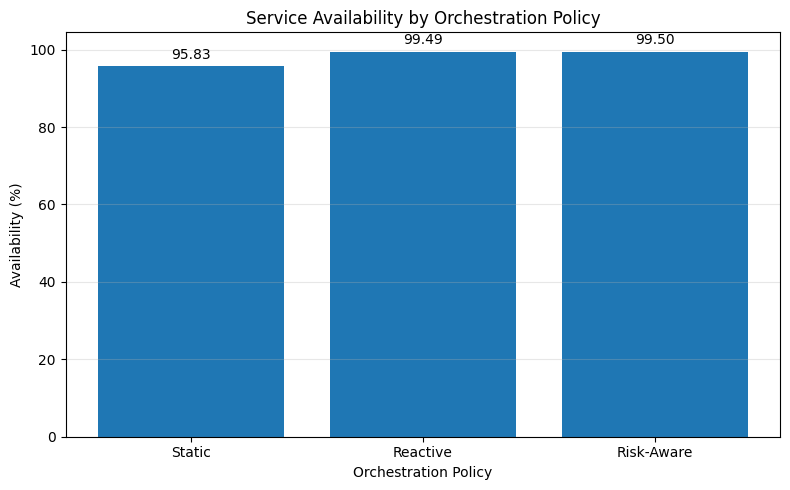

Saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/results/figures/policy_service_availability.png


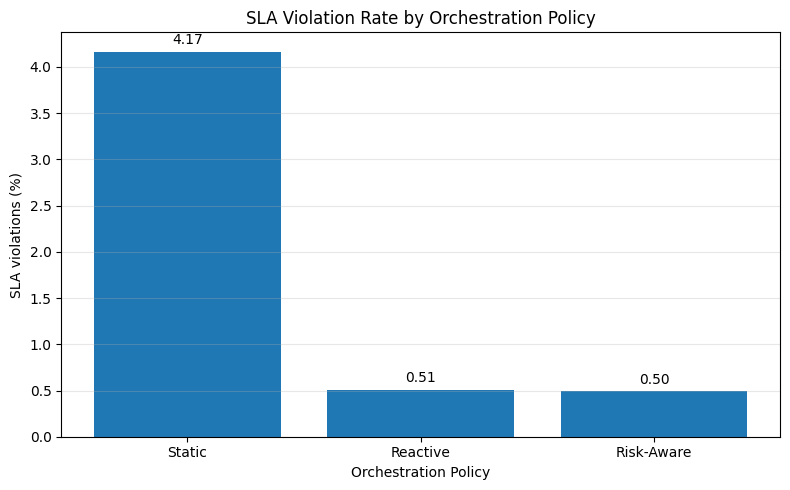

Saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/results/figures/policy_sla_violations.png


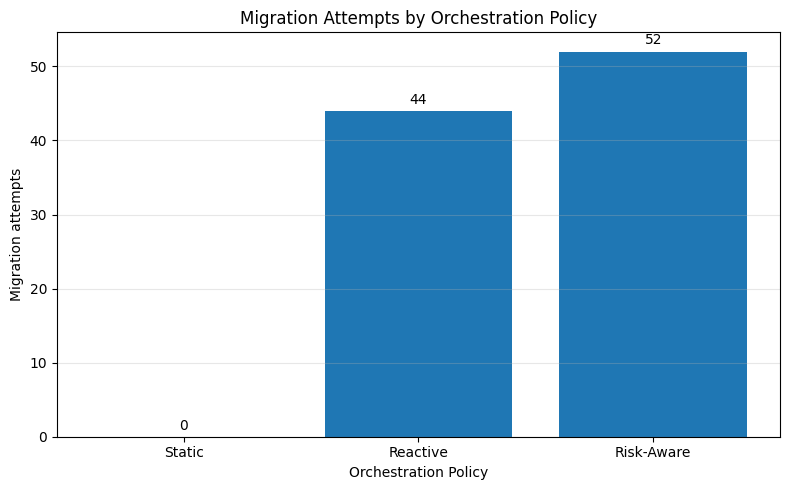

Saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/results/figures/policy_migration_attempts.png


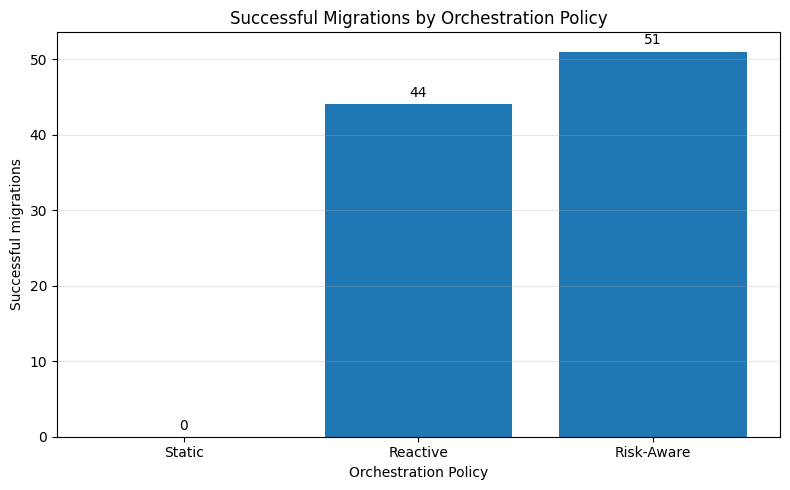

Saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/results/figures/policy_successful_migrations.png


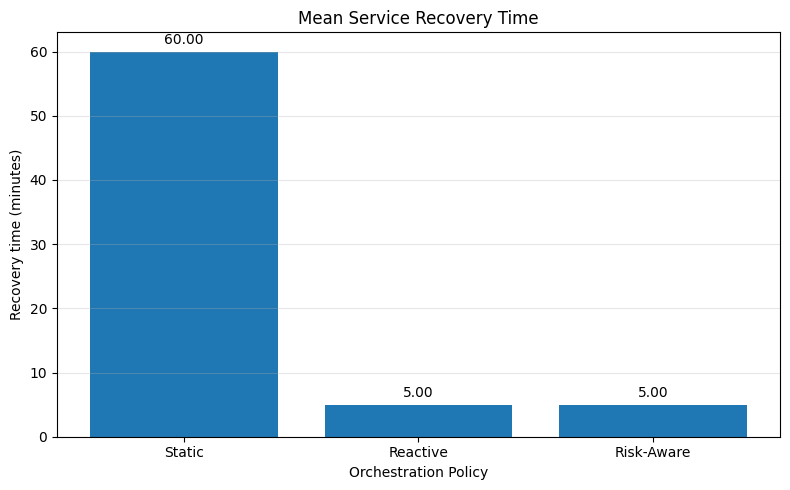

Saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/results/figures/policy_recovery_time.png


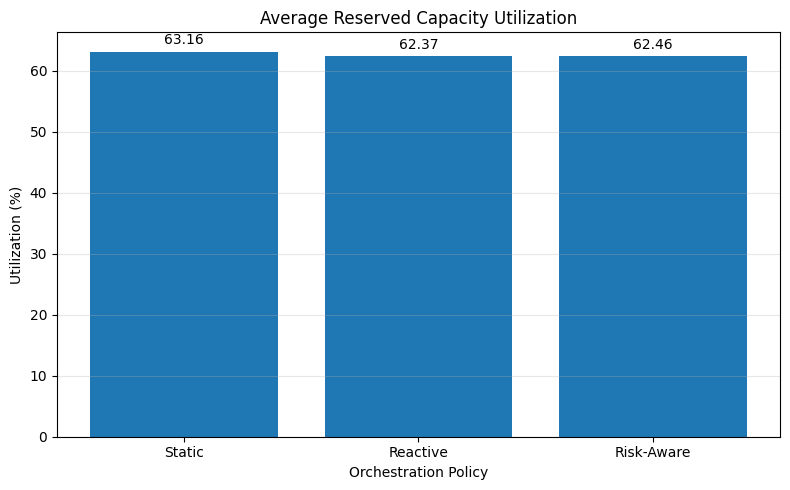

Saved: /content/drive/MyDrive/Multi_Cloud_Orchestration/results/figures/policy_average_capacity_utilization.png

Cell 7E-B completed.
Graphs are saved in: /content/drive/MyDrive/Multi_Cloud_Orchestration/results/figures


In [ ]:

# ============================================================
# CELL 7E-B: POLICY COMPARISON GRAPHS
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")

os.makedirs(FIGURES_DIR, exist_ok=True)

summary = pd.read_csv(
    os.path.join(
        RESULTS_DIR, "orchestration_policy_comparison.csv"
    )
)

# Consistent ordering across all graphs
policy_order = ["Static", "Reactive", "Risk-Aware"]
summary["policy"] = pd.Categorical(
    summary["policy"],
    categories=policy_order,
    ordered=True
)
summary = summary.sort_values("policy")

def save_bar_chart(column, title, ylabel, filename, decimals=2):
    fig, ax = plt.subplots(figsize=(8, 5))

    values = summary[column].astype(float)
    bars = ax.bar(
        summary["policy"].astype(str),
        values
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Orchestration Policy")
    ax.grid(axis="y", alpha=0.3)

    ax.bar_label(
        bars,
        fmt=f"%.{decimals}f",
        padding=3
    )

    fig.tight_layout()

    output_path = os.path.join(FIGURES_DIR, filename)
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", output_path)

# 1. Service availability
save_bar_chart(
    "service_availability_percent",
    "Service Availability by Orchestration Policy",
    "Availability (%)",
    "policy_service_availability.png"
)

# 2. SLA violation rate
save_bar_chart(
    "sla_violation_rate_percent",
    "SLA Violation Rate by Orchestration Policy",
    "SLA violations (%)",
    "policy_sla_violations.png"
)

# 3. Migration attempts
save_bar_chart(
    "migration_attempts",
    "Migration Attempts by Orchestration Policy",
    "Migration attempts",
    "policy_migration_attempts.png",
    decimals=0
)

# 4. Successful migrations
save_bar_chart(
    "successful_migrations",
    "Successful Migrations by Orchestration Policy",
    "Successful migrations",
    "policy_successful_migrations.png",
    decimals=0
)

# 5. Mean recovery time
save_bar_chart(
    "mean_recovery_time_minutes",
    "Mean Service Recovery Time",
    "Recovery time (minutes)",
    "policy_recovery_time.png"
)

# 6. Reserved capacity utilization
save_bar_chart(
    "average_reserved_capacity_utilization_percent",
    "Average Reserved Capacity Utilization",
    "Utilization (%)",
    "policy_average_capacity_utilization.png"
)

print("\nCell 7E-B completed.")
print("Graphs are saved in:", FIGURES_DIR)


## 14. Audit migration and capacity records

Check required output files and review the action/capacity logs.

In [ ]:
# CELL 7E-C: MIGRATION AND CAPACITY AUDIT (FIXED)

import os
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/Multi_Cloud_Orchestration"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

files = {
    "actions": os.path.join(RESULTS_DIR, "orchestration_action_log.csv"),
    "capacity": os.path.join(RESULTS_DIR, "cloud_capacity_utilization.csv"),
    "observations": os.path.join(
        RESULTS_DIR, "orchestration_step_observations.csv.gz"
    ),
}

# Verify that every required file exists before reading it
for name, path in files.items():
    print(f"{name}: {'FOUND' if os.path.isfile(path) else 'MISSING'}")
    print(f"  {path}")

missing = [name for name, path in files.items() if not os.path.isfile(path)]

if missing:
    print("\nSome files are missing. Stop here and send me this output.")
else:
    actions = pd.read_csv(files["actions"])
    capacity = pd.read_csv(files["capacity"])
    observations = pd.read_csv(files["observations"])

    print("\nACTION LOG COLUMNS:")
    print(actions.columns.tolist())

    print("\nCAPACITY FILE COLUMNS:")
    print(capacity.columns.tolist())

    print("\nOBSERVATION FILE COLUMNS:")
    print(observations.columns.tolist())

    print("\nMIGRATION ACTION COUNTS:")
    if {"policy", "action"}.issubset(actions.columns):
        print(
            actions.groupby(["policy", "action"])
            .size()
            .rename("count")
            .reset_index()
            .to_string(index=False)
        )
    else:
        print(actions.head().to_string(index=False))

    print("\nCAPACITY SNAPSHOT PREVIEW:")
    print(capacity.head(10).to_string(index=False))

    print("\nAUDIT INSPECTION COMPLETED.")

actions: FOUND
  /content/drive/MyDrive/Multi_Cloud_Orchestration/results/orchestration_action_log.csv
capacity: FOUND
  /content/drive/MyDrive/Multi_Cloud_Orchestration/results/cloud_capacity_utilization.csv
observations: FOUND
  /content/drive/MyDrive/Multi_Cloud_Orchestration/results/orchestration_step_observations.csv.gz

ACTION LOG COLUMNS:
['policy', 'step', 'vm_id', 'action', 'reason', 'source_cloud', 'target_cloud', 'status', 'risk_score']

CAPACITY FILE COLUMNS:
['policy', 'step', 'cloud', 'allocated_units', 'capacity_units', 'utilization_percent', 'cloud_healthy']

OBSERVATION FILE COLUMNS:
['policy', 'step', 'vm_id', 'cloud', 'actual_cpu', 'predicted_cpu', 'anomaly_flag', 'risk_score', 'cloud_healthy', 'migration_pending', 'service_available', 'latency_ms', 'sla_violation', 'step_cost_units']

MIGRATION ACTION COUNTS:
    policy    action  count
  Reactive migration     88
Risk-Aware migration    104

CAPACITY SNAPSHOT PREVIEW:
policy  step   cloud  allocated_units  capacity

## 15. Reconcile capacity and migration results

Perform final consistency checks across the recorded results.

In [ ]:
# CELL 7E-D: CAPACITY AND MIGRATION RECONCILIATION

import os
import pandas as pd

R = "/content/drive/MyDrive/Multi_Cloud_Orchestration/results"

actions = pd.read_csv(os.path.join(R, "orchestration_action_log.csv"))
capacity = pd.read_csv(os.path.join(R, "cloud_capacity_utilization.csv"))
summary = pd.read_csv(os.path.join(R, "orchestration_policy_comparison.csv"))

# 1. Capacity snapshot check
capacity["excess_units"] = (
    capacity["allocated_units"] - capacity["capacity_units"]
).clip(lower=0)

print("1. RECORDED CAPACITY CHECK")
print("Rows checked:", len(capacity))
print("Rows over capacity:", int((capacity["excess_units"] > 0).sum()))
print("\nPeak utilization by policy:")
print(
    capacity.groupby("policy")["utilization_percent"]
    .max().round(2).to_string()
)

# 2. Migration action status counts
print("\n2. ACTION LOG STATUS COUNTS")
print(
    actions.groupby(["policy", "status"])
    .size().unstack(fill_value=0).to_string()
)

print("\n3. ACTION LOG REASON COUNTS")
print(
    actions.groupby(["policy", "reason"])
    .size().unstack(fill_value=0).to_string()
)

# 3. Compare logged rows to summary metrics
print("\n4. SUMMARY MIGRATION METRICS")
cols = [
    c for c in [
        "policy", "migration_attempts",
        "successful_migrations", "failed_migrations"
    ] if c in summary.columns
]
print(summary[cols].to_string(index=False))

print("\nAudit complete. These checks use recorded snapshots;")
print("they do not prove that temporary migration reservations never exceeded capacity.")

1. RECORDED CAPACITY CHECK
Rows checked: 2592
Rows over capacity: 0

Peak utilization by policy:
policy
Reactive      100.00
Risk-Aware    100.00
Static         71.43

2. ACTION LOG STATUS COUNTS
status      failed_target_unhealthy  initiated  success
policy                                                 
Reactive                          0         44       44
Risk-Aware                        1         52       51

3. ACTION LOG REASON COUNTS
reason      anomaly_detected  cloud_failure
policy                                     
Reactive                   0             88
Risk-Aware                18             86

4. SUMMARY MIGRATION METRICS
    policy  migration_attempts  successful_migrations  failed_migrations
    Static                   0                      0                  0
  Reactive                  44                     44                  0
Risk-Aware                  52                     51                  1

Audit complete. These checks use recorded snapshots;